# Mid-infrared (MIR) spectra with spectraxai

MIR spectra are indexed by **wavenumber** in cm⁻¹ rather than wavelength, are usually stored from high to low wavenumber, and are conventionally plotted with the wavenumber axis running from high (left) to low (right). This notebook shows how spectraxai handles them:

- `Dataset(..., spectral_unit="cm-1")` labels every spectral plot "Wavenumber (cm⁻¹)" and draws the axis from high to low, whichever order the columns are stored in;
- pre-processing, models, splits and feature selection work in either column order (continuum removal uses the actual wavenumbers).

**Data.** `load_GB_MIR()` returns diffuse reflectance MIR absorbance spectra of 427 topsoils from the Countryside Survey of Great Britain 2007 (Keith et al., 2020, NERC EIDC, [doi:10.5285/d66ca0a6-403d-4f5a-bef1-8ee177f1e1b3](https://doi.org/10.5285/d66ca0a6-403d-4f5a-bef1-8ee177f1e1b3); contains public sector information licensed under the Open Government Licence v3.0).

In [1]:
from spectraxai.data import load_GB_MIR

mir = load_GB_MIR()
print(mir.X.shape, "wavenumbers from", mir.wavelengths[0], "to", mir.wavelengths[-1], "cm-1")

(427, 467) wavenumbers from 3996.49 to 399.26 cm-1


## A target to work with

The packaged spectra come **without soil properties**. To demonstrate modelling, we build a **semi-synthetic** target: the height of the aliphatic C–H stretching band (2840–2940 cm⁻¹, associated with soil organic matter) above a nearby baseline (2600–2700 cm⁻¹), plus a little noise. With your own data, use the measured property instead.

In [2]:
import numpy as np

from spectraxai.dataset import Dataset

w = mir.wavelengths
ch_band = (w >= 2840) & (w <= 2940)
baseline = (w >= 2600) & (w <= 2700)
rng = np.random.default_rng(0)
ch = mir.X[:, ch_band].mean(axis=1) - mir.X[:, baseline].mean(axis=1)
ch = ch + rng.normal(0, 0.02 * ch.std(), ch.shape)

dataset = Dataset(mir.X, ch, X_names=list(w), Y_names=["C-H band"], spectral_unit="cm-1")
dataset.spectral_label

'Wavenumber (cm$^{-1}$)'

## Mean spectrum

The axis is drawn from high to low wavenumber automatically. Excluded bands may be given as wavenumbers usually are, high to low: here the atmospheric CO₂ band.

/Users/nikos/anaconda3/envs/spectraxai/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Text(0, 0.5, 'Absorbance')

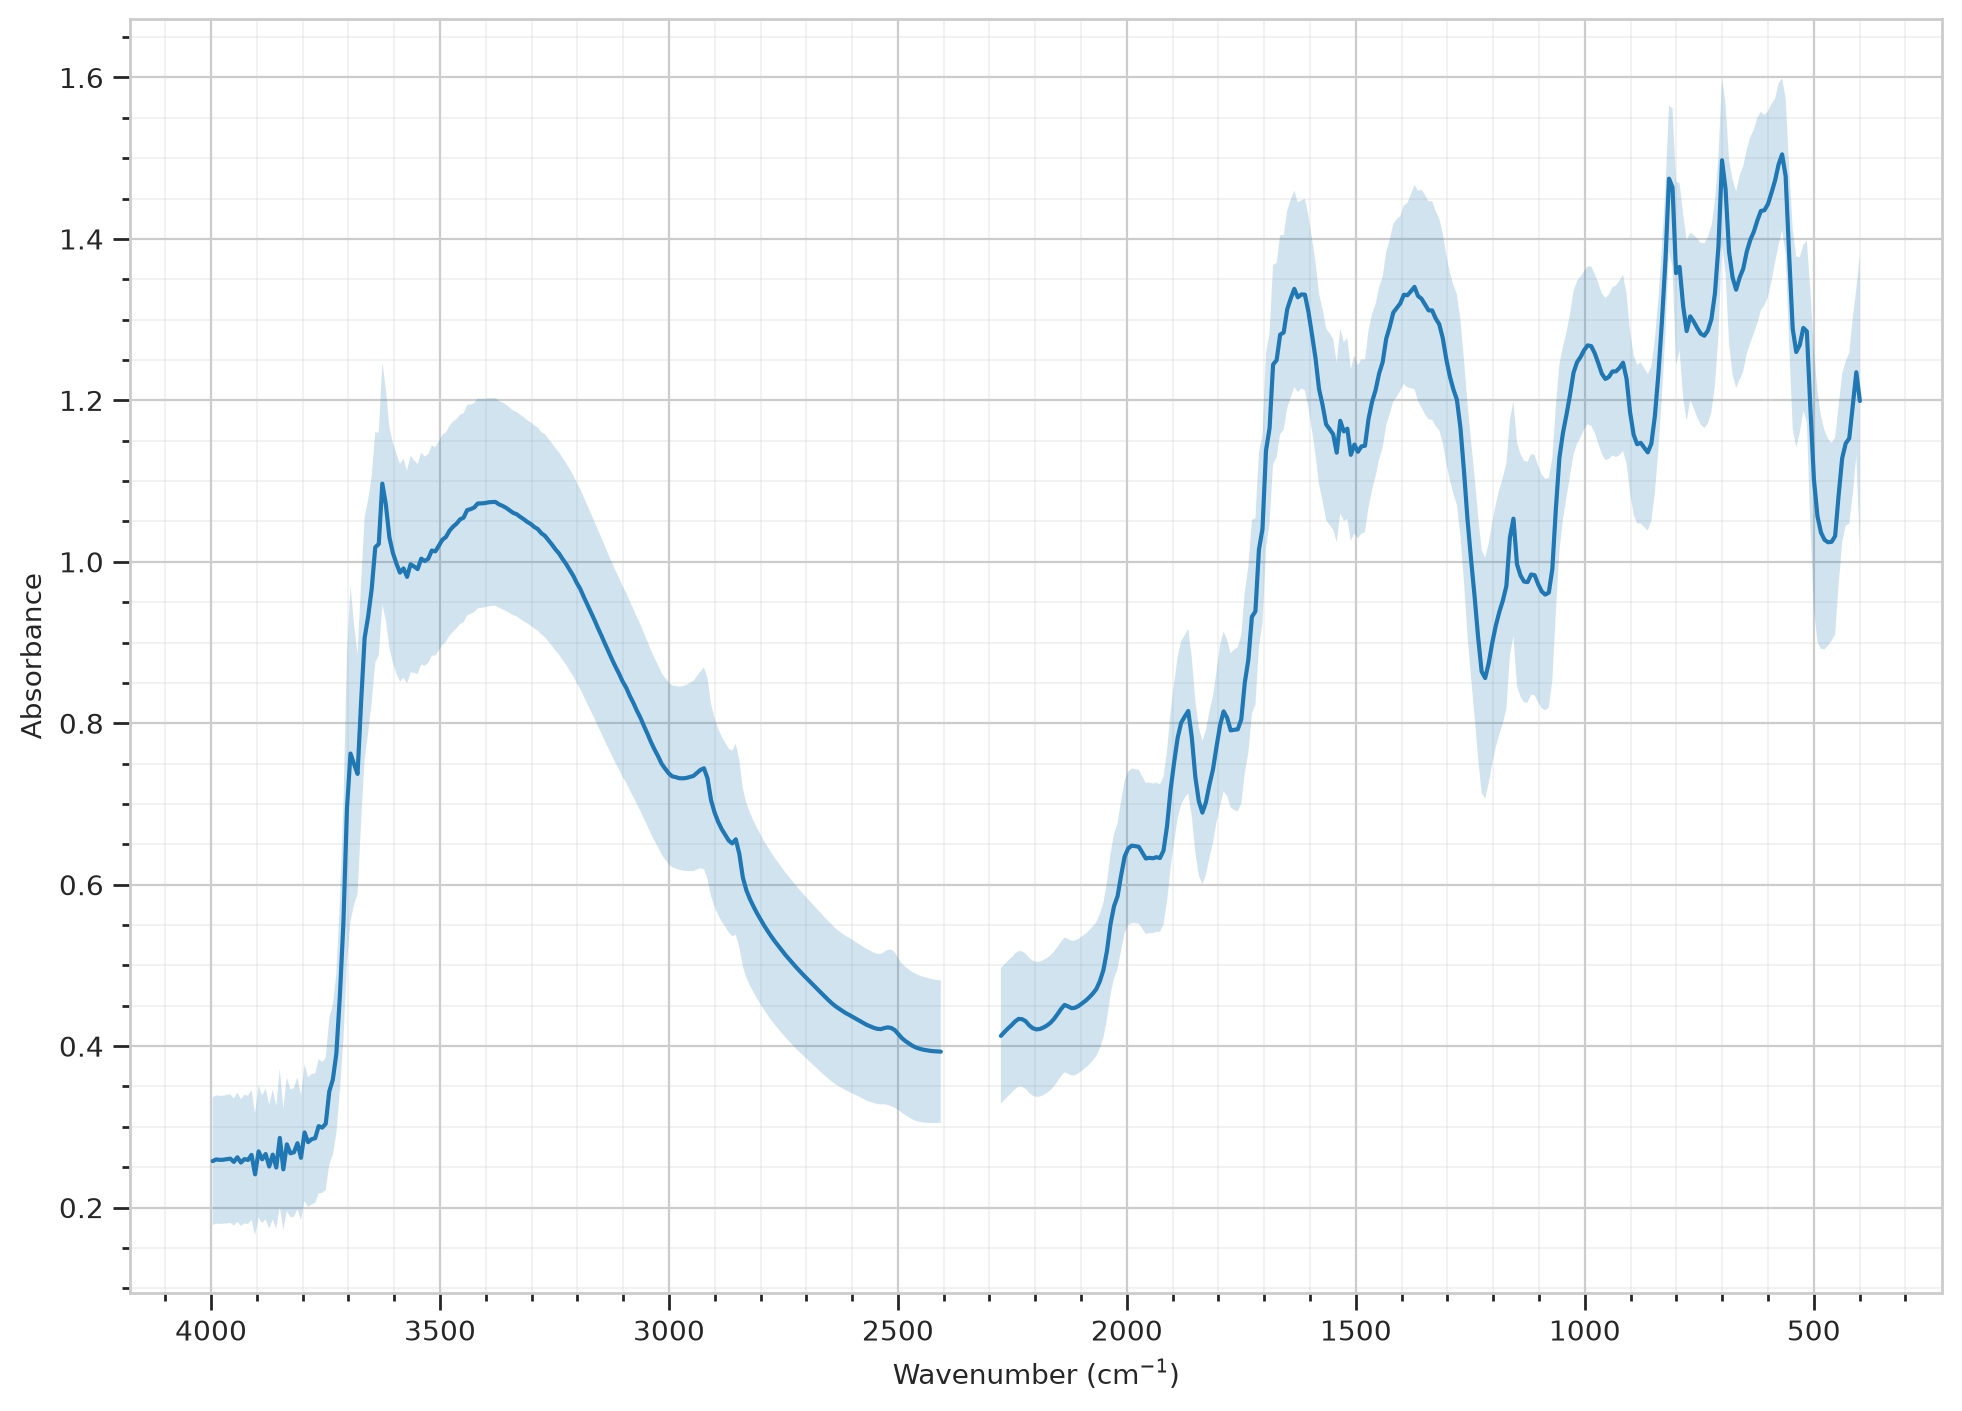

In [3]:
from spectraxai.explain import PreHocAnalysis

pre = PreHocAnalysis(dataset)
ax = pre.mean_spectrum(excluded_bands=[(2400, 2280)])
ax.set_ylabel("Absorbance")

## Comparing pre-treatments in one figure

Every plot accepts `ax`, so pre-treatments can be compared side by side. Continuum removal uses the wavenumbers, so it gives the same result whether the columns are stored high-to-low or low-to-high.

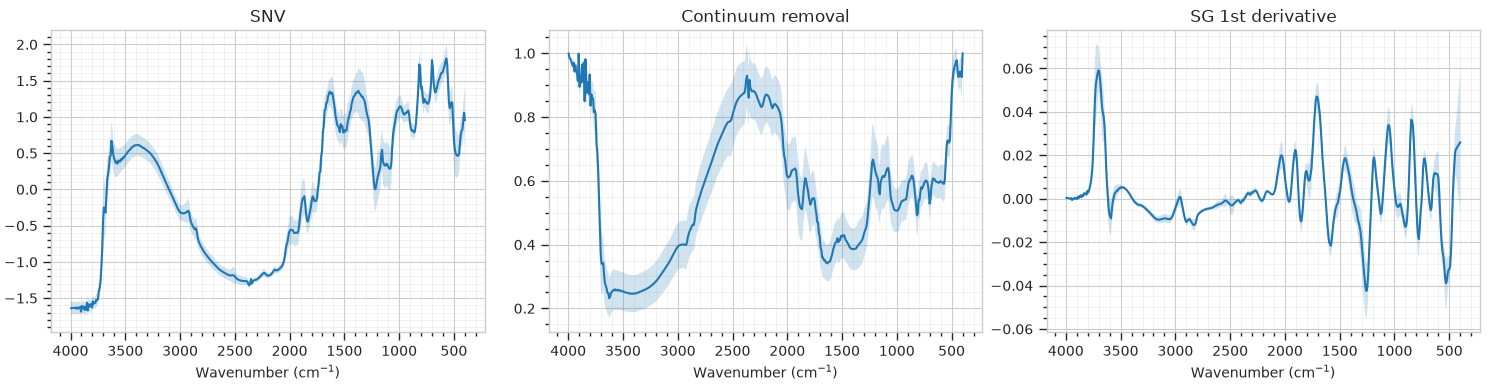

In [4]:
import matplotlib.pyplot as plt

from spectraxai.plotting import style
from spectraxai.spectra import SpectralPreprocessing as SP

treatments = {
    "SNV": SP.SNV,
    "Continuum removal": SP.CR,
    "SG 1st derivative": (SP.SG1, {"window_length": 11, "polyorder": 2}),
}
with style():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (name, method) in zip(axes, treatments.items()):
        PreHocAnalysis(dataset.preprocess(method)).mean_spectrum(ax=ax)
        ax.set_title(name)
    fig.tight_layout()

## Splitting

Kennard–Stone and conditioned Latin hypercube sampling (on the principal components of the spectra) both work on the 467 wavenumbers.

In [5]:
from spectraxai.dataset import DatasetSplit

idx_trn, idx_tst = dataset.train_test_split(DatasetSplit.CLHS, 0.75, random_state=0)
len(idx_trn), len(idx_tst)

(320, 107)

## Models and pre-treatments

In [6]:
import pandas as pd

from spectraxai.models import Model, StandardModel

preprocesses = [SP.NONE, SP.SNV, [SP.CR, SP.SNV]]
results = pd.concat(
    [
        StandardModel(model, random_state=0).fit_and_predict_multiple(
            dataset, preprocesses, idx_trn=idx_trn
        )
        for model in (Model.PLS, Model.RIDGE)
    ],
    ignore_index=True,
)
results[["model_name", "pre_process", "RMSE", "R2", "RPIQ"]]

,model_name,pre_process,RMSE,R2,RPIQ
0,PLS,NONE,0.000950,0.999015,40.927529
1,PLS,SNV,0.007343,0.941112,5.293667
2,PLS,"[continuum-removal, SNV]",0.008514,0.920831,4.565570
3,RIDGE,NONE,0.000850,0.999211,45.739865
4,RIDGE,SNV,0.006714,0.950770,5.789678
5,RIDGE,"[continuum-removal, SNV]",0.008241,0.925835,4.717075


## Which wavenumbers matter?

The 15 wavenumbers most correlated with the target fall on the C–H band and its baseline, as they should.

[1658. 2854. 2862. 2877. 2893. 2900. 2908. 2916. 2924. 2931. 2939. 2947.
 2954. 2962. 2970.]


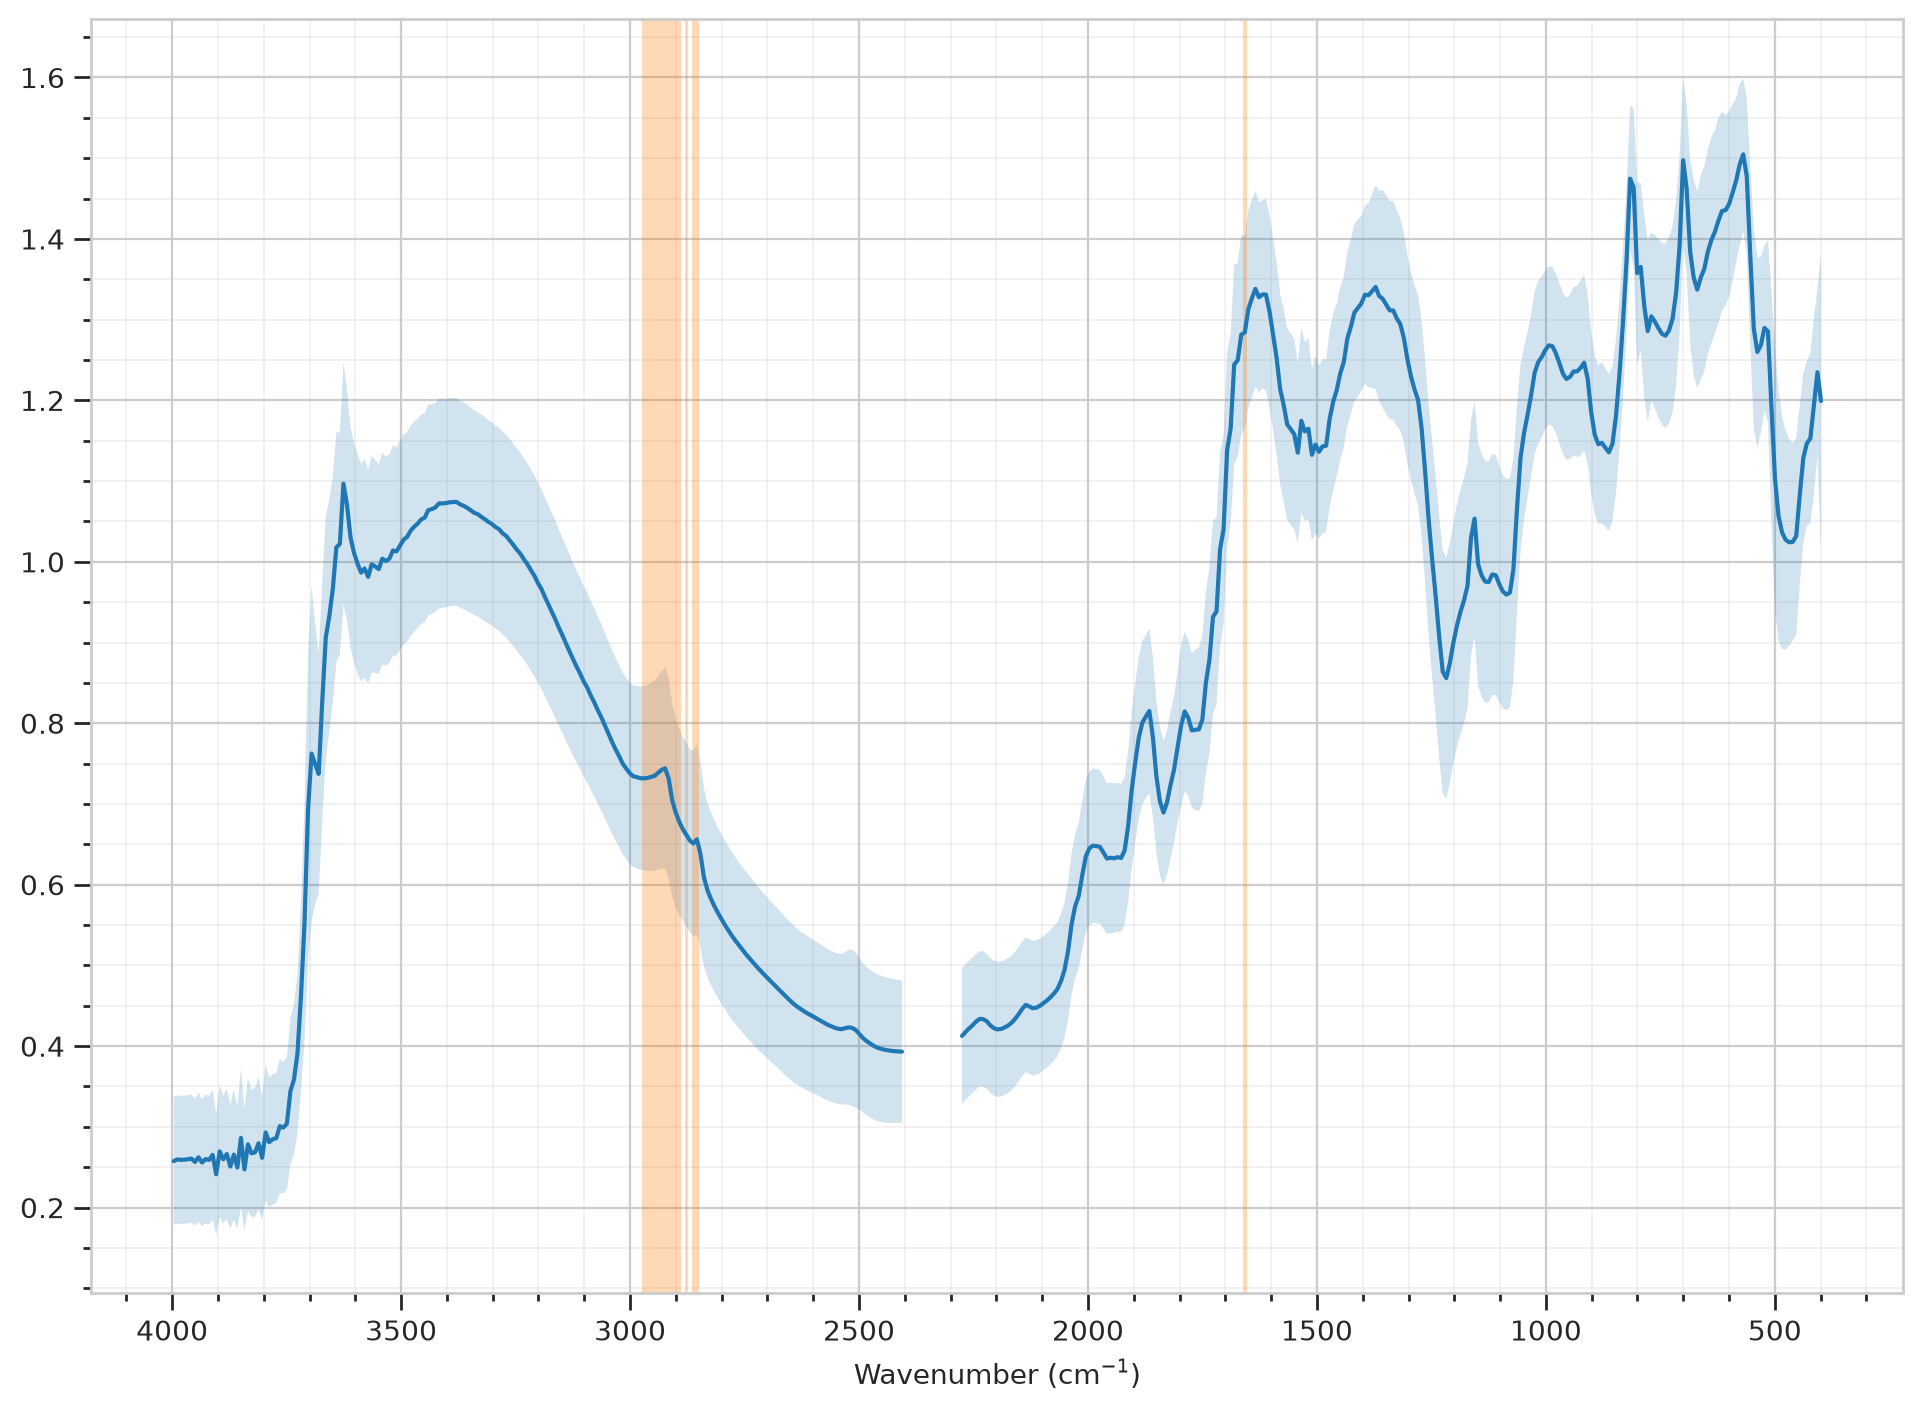

In [7]:
from spectraxai.selection import SelectKBest

training = dataset.subset(idx_trn)
kbest = SelectKBest(k=15).fit(training)
print(np.sort(kbest.selected_wavelengths(dataset)).round(0))
ax = pre.plot_selected_bands(kbest, excluded_bands=[(2400, 2280)])

Model-based importance tells a more nuanced story: MIR bands are strongly collinear, so PLS spreads the importance (VIP) over many regions that carry the same information. The bar plot also puts the highest wavenumber on the left.

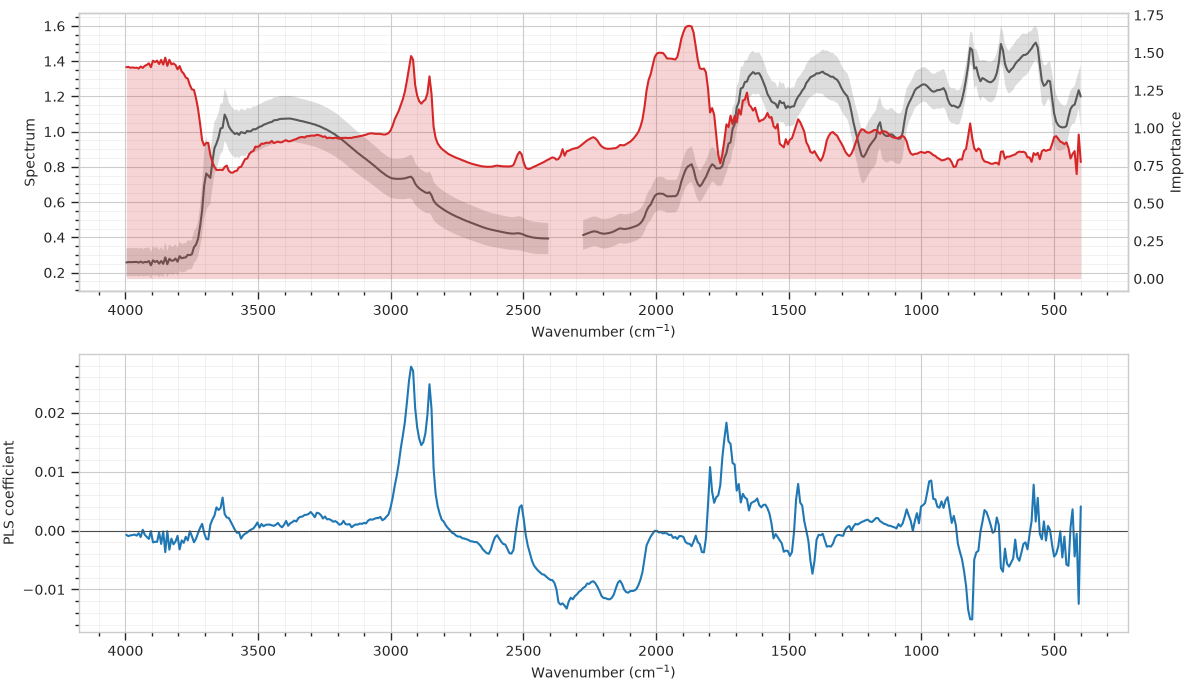

In [8]:
from spectraxai.explain import PostHocAnalysis

pls = StandardModel(Model.PLS, init_hyperparameters={"n_components": 8}).fit(training)
post = PostHocAnalysis(dataset)
with style():
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
    post.plot_importance_spectrum(pls, ax=axes[0], excluded_bands=[(2400, 2280)])
    post.plot_pls_coefficients(pls, ax=axes[1])
    fig.tight_layout()